# 21 — Receptor layer: signed binding matrix B, receptor abundance R, competence

**Summary.** 85 of 90 cytokines have annotated receptors (evidence A, ≥ 2 of CellPhoneDB/CellChatDB/ICELLNET: 83; B: Decorin; C: Noggin, whose 16 BMP-receptor subunits are inherited via its cofactor targets). **No annotation:** ADSF (RETN), IL-17D, IL-32-beta, LT-alpha1-beta2, LT-alpha2-beta1 (OmniPath has no entry; the LT heteromers are not annotated as an LTA_LTB complex). Four antagonists carry sign −1 from the CellChatDB-cofactors inhibition edges: IL-1Ra, IL-36Ra, Noggin, Decorin; the assertion that IL-1Ra and IL-36Ra are negative passes (IL-1Ra vs IL-1β: signed distance 2.0, unsigned 0.0). Competence uses the best complex of min-over-subunits; the mean badly overstates IL-2 competence in B naive and monocytes (min 0.7–0.9 vs mean 2.3–2.9 log1p CPM). Gaps: GFRA4 is absent from the Parse gene annotation, so PSPN has no competence value (NaN); IFN-alpha1 is annotated under the alias IFNA13.


CPU only; no model code. Builds the two objects the gate needs: **B** (ligand × receptor subunit, signed) and **competence** (ligand × donor × cell type).

**Roles of resources.** OmniPath `LigRecExtra` (ligand–receptor, `license="academic"`) aggregates many resources; the *curated trio* **CellPhoneDB, CellChatDB, ICELLNET** defines the receptor complexes (evidence A: ≥ 2 of the trio, B: 1 of the trio). Ligands with no trio edge fall back to other OmniPath resources (evidence C, `n_sources ≥ 3`, direct ligand→receptor only). Sign comes from **CellChatDB-cofactors** (OmniPath intercell resource). NicheNet is **not used** in this notebook (so it stays free for notebook 22).
Receptor abundance: Parse **PBS pseudobulks** (raw counts, all ~40k genes), taken out of `pseudobulks_20260203.zip` with HTTP range requests (18 members, 174 MB; 117 MB transferred). Licence **CC BY-NC 4.0**.

In [1]:
import numpy as np, pandas as pd, anndata as ad, os, scipy.sparse as sp, omnipath as op
import matplotlib.pyplot as plt
pd.set_option("display.width",220,"display.max_columns",30,"display.max_rows",200,"display.max_colwidth",80)
rel=pd.read_csv("../data/reliability.csv",index_col=0); LIG=list(rel.index); assert len(LIG)==90
# cytokine name -> gene symbol(s); heteromers list every chain. IFN-alpha1 -> IFNA13: OmniPath files the IFNA1 protein under IFNA13 (identical protein), IFNA1 itself has no entries.
GENES={'4-1BBL':'TNFSF9','ADSF':'RETN','APRIL':'TNFSF13','BAFF':'TNFSF13B','C3a':'C3','C5a':'C5','CD27L':'CD70','CD30L':'TNFSF8','CD40L':'CD40LG',
 'CT-1':'CTF1','Decorin':'DCN','EGF':'EGF','EPO':'EPO','FGF-beta':'FGF2','FLT3L':'FLT3LG','FasL':'FASLG','G-CSF':'CSF3','GDNF':'GDNF','GITRL':'TNFSF18',
 'GM-CSF':'CSF2','HGF':'HGF','IFN-alpha1':'IFNA13','IFN-beta':'IFNB1','IFN-epsilon':'IFNE','IFN-gamma':'IFNG','IFN-lambda1':'IFNL1','IFN-lambda2':'IFNL2',
 'IFN-lambda3':'IFNL3','IFN-omega':'IFNW1','IGF-1':'IGF1','IL-1-alpha':'IL1A','IL-1-beta':'IL1B','IL-10':'IL10','IL-11':'IL11','IL-12':'IL12A+IL12B',
 'IL-13':'IL13','IL-15':'IL15','IL-16':'IL16','IL-17A':'IL17A','IL-17B':'IL17B','IL-17C':'IL17C','IL-17D':'IL17D','IL-17E':'IL25','IL-17F':'IL17F',
 'IL-18':'IL18','IL-19':'IL19','IL-1Ra':'IL1RN','IL-2':'IL2','IL-20':'IL20','IL-21':'IL21','IL-22':'IL22','IL-23':'IL23A+IL12B','IL-24':'IL24','IL-26':'IL26',
 'IL-27':'IL27+EBI3','IL-3':'IL3','IL-31':'IL31','IL-32-beta':'IL32','IL-33':'IL33','IL-34':'IL34','IL-35':'IL12A+EBI3','IL-36-alpha':'IL36A','IL-36Ra':'IL36RN',
 'IL-4':'IL4','IL-5':'IL5','IL-6':'IL6','IL-7':'IL7','IL-8':'CXCL8','IL-9':'IL9','LIF':'LIF','LIGHT':'TNFSF14','LT-alpha1-beta2':'LTA+LTB','LT-alpha2-beta1':'LTA+LTB',
 'Leptin':'LEP','M-CSF':'CSF1','Noggin':'NOG','OSM':'OSM','OX40L':'TNFSF4','PRL':'PRL','PSPN':'PSPN','RANKL':'TNFSF11','SCF':'KITLG','TGF-beta1':'TGFB1',
 'TL1A':'TNFSF15','TNF-alpha':'TNF','TPO':'THPO','TRAIL':'TNFSF10','TSLP':'TSLP','TWEAK':'TNFSF12','VEGF':'VEGFA'}
assert set(GENES)==set(LIG), set(LIG)^set(GENES)
LG={k:frozenset(v.split("+")) for k,v in GENES.items()}
ALL_LIG_GENES=set().union(*LG.values())
TRIO={"CellPhoneDB","CellChatDB","ICELLNET"}
# known non-signalling decoys: kept in the long table, flagged, excluded from B and from competence
DECOY={"IL1R2","IL13RA2","TNFRSF11B","TNFRSF6B","TNFRSF10C","TNFRSF10D","IL22RA2"}
df=op.interactions.LigRecExtra.get(genesymbols=True, license="academic")
df["src_set"]=df.source_genesymbol.str.split("_").map(frozenset)
df["res"]=df.sources.str.split(";").map(set)
print(df.shape)

/users/scratch1/pavelabramau/envs/cellflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(6658, 19)


## 1. Edges per cytokine (resource of origin kept)

In [2]:
rows=[]
for lig,lg in LG.items():
    e=df[df.src_set==lg]
    e_trio=e[e.res.map(lambda s:bool(s&TRIO))]
    if len(e_trio):
        for _,r in e_trio.iterrows():
            toks=[t for t in r.target_genesymbol.split("_") if t not in ALL_LIG_GENES]
            if not toks: continue
            rows.append(dict(ligand=lig,complex="_".join(sorted(toks)),subunits=toks,trio_sources=";".join(sorted(r.res&TRIO)),
                             all_sources=r.sources,n_sources=r.n_sources,tier="trio"))
    else:
        for _,r in e[(e.n_sources>=3)&(~e.target_genesymbol.str.contains("_"))&(e.is_directed)].iterrows():
            if r.target_genesymbol in ALL_LIG_GENES: continue
            rows.append(dict(ligand=lig,complex=r.target_genesymbol,subunits=[r.target_genesymbol],trio_sources="",all_sources=r.sources,n_sources=r.n_sources,tier="other"))
E=pd.DataFrame(rows)
# merge duplicate complexes (same ligand, same complex from several trio rows)
E=E.groupby(["ligand","complex"],as_index=False).agg(subunits=("subunits","first"),trio_sources=("trio_sources",lambda s:";".join(sorted({x for v in s for x in v.split(";") if x}))),
    all_sources=("all_sources",lambda s:";".join(sorted({x for v in s for x in v.split(";")}))),n_sources=("n_sources","max"),tier=("tier","first"))
E["decoy"]=E.subunits.map(lambda s:any(x in DECOY for x in s))
print(len(E),"ligand-complex edges for",E.ligand.nunique(),"cytokines")
E[E.ligand.isin(["IL-2","IL-15","IL-1-beta","IL-12","IL-1Ra","IL-36Ra"])][["ligand","complex","trio_sources","tier","decoy"]]

159 ligand-complex edges for 85 cytokines


,ligand,complex,trio_sources,tier,decoy
57,IL-1-beta,IL1R1_IL1RAP,CellChatDB;CellPhoneDB;ICELLNET,trio,False
58,IL-1-beta,IL1R2,CellChatDB,trio,True
59,IL-1-beta,IL1R2_IL1RAP,CellPhoneDB,trio,True
62,IL-12,IL12RB1_IL12RB2,CellChatDB;CellPhoneDB;ICELLNET,trio,False
67,IL-15,IL15RA_IL2RB_IL2RG,CellChatDB;CellPhoneDB;ICELLNET,trio,False
77,IL-1Ra,IL1R1,ICELLNET,trio,False
78,IL-1Ra,IL1R1_IL1RAP,CellPhoneDB,trio,False
79,IL-1Ra,IL1R2,ICELLNET,trio,True
80,IL-1Ra,IL1R2_IL1RAP,CellPhoneDB,trio,True
81,IL-2,IL2RA_IL2RB_IL2RG,CellChatDB;CellPhoneDB;ICELLNET,trio,False


## 2. Sign from CellChatDB cofactors; assert IL-1Ra and IL-36Ra negative

In [3]:
cof=df[df.res.map(lambda s:"CellChatDB-cofactors" in s)]
print("cofactor edges:",len(cof)," inhibitory (not stimulatory):",(cof.is_inhibition&~cof.is_stimulation).sum())
ant={}
for lig,lg in LG.items():
    c=cof[(cof.src_set==lg)&cof.is_inhibition&~cof.is_stimulation]
    if len(c): ant[lig]=sorted(c.target_genesymbol)
print("antagonists among the 90 (CellChatDB-cofactors inhibition edges):")
for k,v in ant.items(): print(" ",k,"->",v)
# expand: antagonist is -1 on its own receptors and on the receptors of the ligands it neutralises
def trio_subunits(gene_set_or_gene):
    lg=gene_set_or_gene if isinstance(gene_set_or_gene,frozenset) else frozenset([gene_set_or_gene])
    e=df[(df.src_set==lg)&df.res.map(lambda s:bool(s&TRIO))]
    return sorted({t for x in e.target_genesymbol for t in x.split("_") if t not in ALL_LIG_GENES and t not in DECOY})
extra=[]
for lig,tg in ant.items():
    for t in tg:
        subs=trio_subunits(t)
        if not subs: subs=[t]   # target is itself a receptor / binding partner
        for s in subs: extra.append(dict(ligand=lig,complex=s,subunits=[s],trio_sources="CellChatDB-cofactors(via %s)"%t,all_sources="CellChatDB-cofactors",n_sources=1,tier="cofactor",decoy=s in DECOY))
E=pd.concat([E,pd.DataFrame(extra)],ignore_index=True)
E["antagonist"]=E.ligand.isin(ant); E["sign"]=np.where(E.antagonist,-1,1)
E["tier"]=E.tier.astype(str)
# long subunit-level table
L=E.explode("subunits").rename(columns={"subunits":"subunit"})
L["required_in_complex"]=L.complex.str.contains("_")|True      # every subunit of a listed complex is required for that complex
L=L[~L.decoy].copy()
L=L.groupby(["ligand","subunit","sign"],as_index=False).agg(complexes=("complex",lambda s:";".join(sorted(set(s)))),n_complexes=("complex","nunique"),
    trio_sources=("trio_sources",lambda s:";".join(sorted({x for v in s for x in v.split(";") if x}))),all_sources=("all_sources",lambda s:";".join(sorted({x for v in s for x in v.split(";")}))),
    tier=("tier",lambda s:";".join(sorted(set(s)))))
B=L.pivot_table(index="ligand",columns="subunit",values="sign",aggfunc="min",fill_value=0).reindex(LIG).fillna(0)
for k in ["IL-1Ra","IL-36Ra"]:
    assert (B.loc[k][B.loc[k]!=0]<0).all() and (B.loc[k]!=0).any(), k
assert (B.loc["IL-1Ra",["IL1R1","IL1RAP"]]<0).all() and (B.loc["IL-36Ra",["IL1RL2","IL1RAP"]]<0).all()
print("ASSERT OK: IL-1Ra and IL-36Ra rows are negative:"); 
print(B.loc[["IL-1Ra","IL-36Ra","IL-1-beta","IL-36-alpha"]].loc[:,lambda d:(d!=0).any()].T)
print("B shape",B.shape," antagonist rows:",sorted(B.index[(B<0).any(axis=1)]))

cofactor edges: 682  inhibitory (not stimulatory): 508


antagonists among the 90 (CellChatDB-cofactors inhibition edges):
  Decorin -> ['TGFB1', 'TGFB2', 'TGFB3']
  IL-1Ra -> ['IL1A', 'IL1B']
  IL-36Ra -> ['IL36A', 'IL36B', 'IL36G']
  Noggin -> ['BMP15', 'BMP2', 'BMP4', 'BMP5', 'BMP6', 'BMP7', 'BMP8A', 'BMP8B', 'GDF5', 'GDF6', 'GDF7']
ASSERT OK: IL-1Ra and IL-36Ra rows are negative:
ligand   IL-1Ra  IL-36Ra  IL-1-beta  IL-36-alpha
subunit                                         
IL1R1      -1.0      0.0        1.0          0.0
IL1RAP     -1.0     -1.0        1.0          1.0
IL1RL2      0.0     -1.0        0.0          1.0
B shape (90, 120)  antagonist rows: ['Decorin', 'IL-1Ra', 'IL-36Ra', 'Noggin']


## 3. Coverage report (paper figure)

85 of 90 cytokines have annotated receptors; 5 without: ['ADSF', 'IL-17D', 'IL-32-beta', 'LT-alpha1-beta2', 'LT-alpha2-beta1']
{'A': 83, 'none': 5, 'B': 1, 'C': 1}
                              sum  count
family                                  
Chemokine                       1      1
Common β chain                  3      3
Common γ chain/IL-13/TSLP       8      8
Complement                      2      2
Growth factor                  11     11
IL-1                            7      7
IL-10                           5      5
IL-10 (IL-20 subfamily)         1      1
IL-17                           5      6
IL-6/IL-12                     10     10
Interferon                      8      8
Interleukin - non-classified    1      2
Other                           8      9
TNF                            15     17


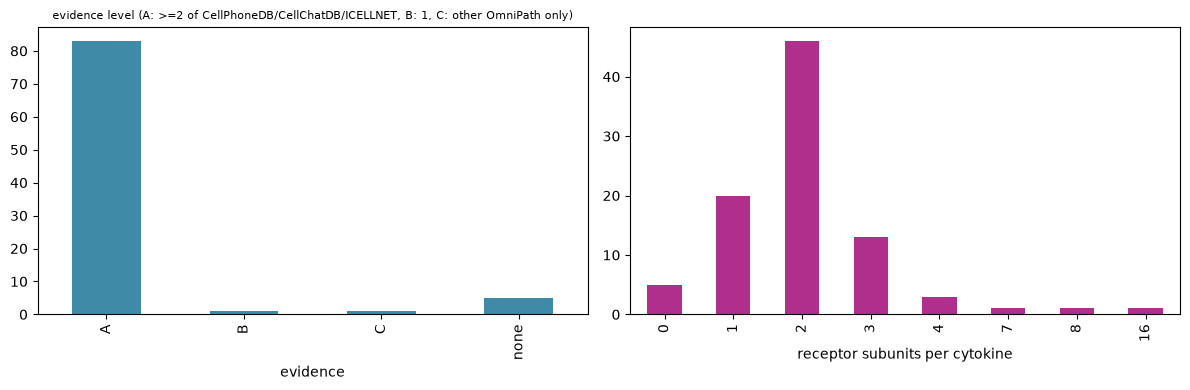

,genes,family,n_subunits,n_complexes,evidence,trio_resources,sign,has_receptor,r_split_half
4-1BBL,TNFSF9,TNF,1,1,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.30
ADSF,RETN,Other,0,0,none,,none,False,0.33
APRIL,TNFSF13,TNF,3,3,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.35
BAFF,TNFSF13B,TNF,3,3,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.37
C3a,C3,Complement,3,3,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.27
C5a,C5,Complement,2,2,A,CellChatDB;CellPhoneDB,agonist (+1),True,0.61
CD27L,CD70,TNF,1,1,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.67
CD30L,TNFSF8,TNF,1,1,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.56
CD40L,CD40LG,TNF,1,1,A,CellChatDB;CellPhoneDB;ICELLNET,agonist (+1),True,0.91
CT-1,CTF1,IL-6/IL-12,2,1,A,CellChatDB;ICELLNET,agonist (+1),True,0.71


In [4]:
def evid(l):
    e=E[(E.ligand==l)&~E.decoy&(E.tier!="cofactor")]
    if not len(e): return "none"
    if e.tier.eq("other").all(): return "C"
    n=len({x for v in e.trio_sources for x in v.split(";") if x}); return "A" if n>=2 else "B"
cov=pd.DataFrame({"genes":[GENES[l] for l in LIG]},index=LIG)
cov["family"]=rel.family
cov["n_subunits"]=(B!=0).sum(axis=1); cov["n_complexes"]=[E[(E.ligand==l)&~E.decoy].complex.nunique() for l in LIG]
cov["evidence"]=[evid(l) for l in LIG]
cov["trio_resources"]=[";".join(sorted({x for v in E[(E.ligand==l)&~E.decoy&(E.tier=="trio")].trio_sources for x in v.split(";") if x})) for l in LIG]
cov["sign"]=np.where((B<0).any(axis=1),"antagonist (-1)",np.where((B!=0).any(axis=1),"agonist (+1)","none"))
cov["has_receptor"]=cov.n_subunits>0
cov["r_split_half"]=rel.r_split_half.round(2)
print(cov.has_receptor.sum(),"of 90 cytokines have annotated receptors;",(~cov.has_receptor).sum(),"without:",list(cov.index[~cov.has_receptor]))
print(cov.evidence.value_counts().to_dict()); print(cov.groupby("family").has_receptor.agg(["sum","count"]))
fig,ax=plt.subplots(1,2,figsize=(12,4)); cov.evidence.value_counts().reindex(["A","B","C","none"]).fillna(0).plot.bar(ax=ax[0],color="#3F8AA6"); ax[0].set_title("evidence level (A: >=2 of CellPhoneDB/CellChatDB/ICELLNET, B: 1, C: other OmniPath only)",fontsize=8)
cov.n_subunits.value_counts().sort_index().plot.bar(ax=ax[1],color="#B12F8C"); ax[1].set_xlabel("receptor subunits per cytokine"); plt.tight_layout(); plt.savefig("../models/21_coverage.png",dpi=130); plt.show()
cov

## 4. Receptor abundance R from Parse PBS pseudobulks (raw counts)

In [5]:
CT_MAP={"B Intermediate/Memory":"Intermediate_B_cell","B Naive":"Naive_B_cell","CD14 Mono":"CD14_Mono","CD16 Mono":"CD16_Mono","CD4 Memory":"CD4_Memory_T_cell_",
 "CD4 Naive":"CD4_Naive_T_cell_","CD8 Memory":"CD8_Memory_T_cell","CD8 Naive":"CD8_Naive_T_cell","HSPC":"HSPC","ILC":"ILC","MAIT":"MAIT","NK":"NK_CD56low",
 "NK CD56bright":"NK_CD56hi","NKT":"NKT","Plasmablast":"Plasmablast","Treg":"Treg","cDC":"cDC","pDC":"pDC"}
SUBS=sorted(B.columns); recs=[]; missing=set()
for ct,nm in CT_MAP.items():
    pb=ad.read_h5ad(f"../data/parse_pseudobulk_PBS/pbulk_{nm}_PBS.h5ad")
    X=pb.X.toarray() if sp.issparse(pb.X) else np.asarray(pb.X)
    cpm=pd.DataFrame(X/X.sum(1,keepdims=True)*1e6,index=pb.obs["donor"].astype(str).values,columns=pb.var_names)
    present=[g for g in SUBS if g in cpm.columns]; missing|=set(SUBS)-set(present)
    d=np.log1p(cpm[present]).reindex(columns=SUBS)
    d.insert(0,"cell_type",ct); d.insert(0,"donor",d.index); d["psbulk_n_cells"]=pb.obs["psbulk_n_cells"].values
    recs.append(d.reset_index(drop=True))
Rab=pd.concat(recs,ignore_index=True)
print("pseudobulk",Rab.shape,"donors:",Rab.donor.nunique(),"cell types:",Rab.cell_type.nunique(),"| subunits not in pseudobulk var:",sorted(missing))
print(Rab.groupby("cell_type").donor.nunique().to_dict())
Rab.to_parquet("../data/receptor_abundance_R.parquet"); Rab.head(3)

pseudobulk (215, 123) donors: 12 cell types: 18 | subunits not in pseudobulk var: ['GFRA4']
{'B Intermediate/Memory': 12, 'B Naive': 12, 'CD14 Mono': 12, 'CD16 Mono': 12, 'CD4 Memory': 12, 'CD4 Naive': 12, 'CD8 Memory': 12, 'CD8 Naive': 12, 'HSPC': 12, 'ILC': 12, 'MAIT': 12, 'NK': 12, 'NK CD56bright': 12, 'NKT': 12, 'Plasmablast': 11, 'Treg': 12, 'cDC': 12, 'pDC': 12}


,donor,cell_type,ACKR1,ACVR1,ACVR2A,ACVR2B,BMP2,BMP4,BMP5,BMP6,BMP7,BMP8A,BMP8B,BMPR1A,BMPR1B,...,TNFRSF10B,TNFRSF11A,TNFRSF12A,TNFRSF13B,TNFRSF13C,TNFRSF14,TNFRSF17,TNFRSF18,TNFRSF1A,TNFRSF1B,TNFRSF25,TNFRSF4,TNFRSF8,TNFRSF9,psbulk_n_cells
0,Donor1,B Intermediate/Memory,0.0,3.969122,2.746050,1.530099,0.0,0.0,0.277095,2.550520,0.101139,0.556762,0.556762,4.346453,0.615965,...,3.865412,1.596945,0.101139,4.981861,3.989027,3.216747,0.556762,1.433395,1.140588,3.994922,0.277095,0.277095,0.493831,0.775065,2007.0
1,Donor10,B Intermediate/Memory,0.0,4.130770,2.453661,1.673555,0.0,0.0,0.000000,1.152325,0.000000,0.685285,0.580801,4.825372,0.331987,...,3.920264,0.866291,0.331987,5.638862,4.152675,3.462863,0.779878,1.960503,1.088116,4.737941,0.945827,0.464113,2.706556,1.596829,940.0
2,Donor11,B Intermediate/Memory,0.0,4.222495,3.129276,2.437061,0.0,0.0,0.000000,2.214383,0.282340,0.682435,0.835046,4.822819,0.502265,...,4.173481,1.449809,0.282340,5.494661,4.645244,3.380383,1.084304,2.178101,0.835046,4.898600,0.282340,0.282340,2.870041,2.752409,889.0


## 5. Competence: min over required subunits (mean kept as sensitivity)

Per ligand, each trio *complex* is one alternative receptor; all of its subunits are required (AND → minimum), alternative complexes are OR (→ best complex). Single-chain receptors are complexes of size 1. Cofactor-derived antagonist edges are treated like complexes. Decoys excluded.

In [6]:
cx={}
for l in LIG:
    e=E[(E.ligand==l)&~E.decoy]
    if len(e): cx[l]=[(r.complex,[s for s in r.subunits if s in SUBS]) for r in e.itertuples()]
rows=[]; Rv=Rab.set_index(["donor","cell_type"])
for l,cl in cx.items():
    best_min=pd.Series(-np.inf,index=Rv.index); best_mean=pd.Series(-np.inf,index=Rv.index); lim=pd.Series("",index=Rv.index,dtype=object); bc=pd.Series("",index=Rv.index,dtype=object)
    for name,subs in cl:
        sub=Rv[subs]
        if sub.isna().all(axis=None) : continue
        mn=sub.min(axis=1,skipna=False); me=sub.mean(axis=1)
        upd=mn.fillna(-1)>best_min
        best_min=best_min.where(~upd,mn); lim=lim.where(~upd,sub.idxmin(axis=1)); bc=bc.where(~upd,name)
        best_mean=np.maximum(best_mean,me)
    out=pd.DataFrame({"ligand":l,"competence_min":best_min.values,"competence_mean":best_mean.values,"limiting_subunit":lim.values,"complex_used":bc.values},index=Rv.index).reset_index()
    rows.append(out)
Comp=pd.concat(rows,ignore_index=True)
Comp.loc[Comp.competence_min==-np.inf,["competence_min","competence_mean"]]=np.nan
Comp=Comp.merge(Rab[["donor","cell_type","psbulk_n_cells"]],on=["donor","cell_type"])
Comp.to_parquet("../data/competence_R.parquet")
B.to_parquet("../data/binding_B.parquet"); L.to_parquet("../data/binding_B_long.parquet"); E.drop(columns=["subunits"]).to_parquet("../data/binding_edges.parquet")
print(Comp.shape, "ligands:",Comp.ligand.nunique()); 
# the IL-2 example
x=Comp[(Comp.ligand=="IL-2")].groupby("cell_type")[["competence_min","competence_mean"]].mean().round(2).assign(gap=lambda d:(d.competence_mean-d.competence_min).round(2)).sort_values("gap",ascending=False)
print("IL-2 (needs IL2RB AND IL2RG): mean vs min across donors, largest gaps"); print(x.head(8))
Comp.groupby("ligand")[["competence_min","competence_mean"]].mean().round(2).sort_values("competence_min").head(12)

(18275, 8) ligands: 85
IL-2 (needs IL2RB AND IL2RG): mean vs min across donors, largest gaps
                       competence_min  competence_mean   gap
cell_type                                                   
B Naive                          0.90             2.86  1.96
CD16 Mono                        0.72             2.37  1.65
CD14 Mono                        0.82             2.32  1.50
pDC                              1.77             3.21  1.44
B Intermediate/Memory            2.56             3.71  1.15
HSPC                             1.89             2.95  1.06
Treg                             4.55             5.57  1.02
Plasmablast                      2.77             3.71  0.94


,competence_min,competence_mean
ligand,,
IL-26,0.05,2.14
IL-19,0.05,1.24
GDNF,0.11,0.29
IL-22,0.12,2.17
IL-20,0.12,1.29
IL-24,0.12,1.29
IL-36-alpha,0.31,1.86
TPO,0.33,0.33
LIF,0.34,2.60


## 6. D_binding

ligands with no annotated receptor (all-zero row -> distance fixed to 1.0 to all others): ['ADSF', 'IL-17D', 'IL-32-beta', 'LT-alpha1-beta2', 'LT-alpha2-beta1']
signed vs unsigned: IL-1Ra to IL-1-beta  signed=2.00 unsigned=0.00


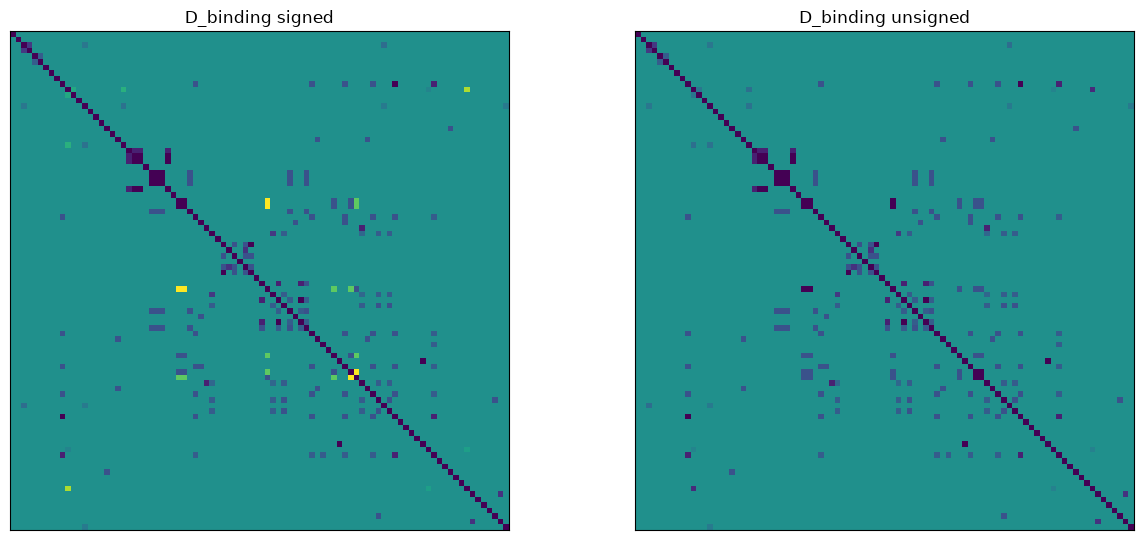

saved


In [7]:
def cosd(M):
    n=np.linalg.norm(M,axis=1); Z=n==0; Mn=M/np.where(n==0,1,n)[:,None]; D=np.clip(1-Mn@Mn.T,0,2)
    D[Z,:]=1.0; D[:,Z]=1.0; np.fill_diagonal(D,0); return D,Z
Ms=B.values.astype(float); Du,zero=cosd(np.abs(Ms)); Ds,_=cosd(Ms)
print("ligands with no annotated receptor (all-zero row -> distance fixed to 1.0 to all others):",list(B.index[zero]))
print("signed vs unsigned: IL-1Ra to IL-1-beta  signed=%.2f unsigned=%.2f"%(Ds[LIG.index('IL-1Ra'),LIG.index('IL-1-beta')],Du[LIG.index('IL-1Ra'),LIG.index('IL-1-beta')]))
pd.DataFrame(Ds,index=LIG,columns=LIG).to_csv("../data/D_binding_signed.csv"); pd.DataFrame(Du,index=LIG,columns=LIG).to_csv("../data/D_binding_unsigned.csv")
np.save("../data/D_binding_signed.npy",Ds); np.save("../data/D_binding_unsigned.npy",Du); np.save("../data/D_binding_zero_rows.npy",zero)
fig,ax=plt.subplots(1,2,figsize=(13,5.5))
for a,D,t in zip(ax,[Ds,Du],["signed","unsigned"]):
    i=ax[0].imshow if False else a.imshow; im=i(D,cmap="viridis",vmin=0,vmax=2); a.set_title("D_binding "+t); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("../models/21_D_binding.png",dpi=120); plt.show()
cov.to_csv("../data/receptor_coverage.csv"); print("saved")